# Reproducing peak-electricity warning experiments

## Summary

This notebook runs the complete reconstructed experiment, including fitting, calibration, testing, and 2,000 paired block-bootstrap replicates. The original implementation was not available. **Reproducibility of this implementation does not mean every number in the earlier manuscript was reproduced.** The comparison file preserves and audits those differences.

At the primary one-hour setting, the implemented protocol obtains 19.5% peak recall and 0.893 false warnings per day for CatBoost regression; logistic regression obtains 14.5% and 0.533. These are empirical results on one facility and one year, not a guarantee of future warning burden.

## Context and methods

The target is a single future 15-minute energy record at a lead of 1, 2, or 4 hours. A peak is consumption above the training-only 90th percentile (85.82 kWh). Six methods share the same training data and calibration budgets.

### Key assumptions

- Original row order is retained. The CSV labels each final midnight record with its preceding source date; timestamps are not repaired or sorted.
- Features, calendar phase, tied-score threshold candidates, and RNG choices are fixed in `METHODOLOGY.md`.
- `legacy` splits by target row to reconstruct the manuscript. `origin_safe` additionally requires the forecast origin to fall in the calibration/test period, removing the boundary availability problem.
- Both protocols report false warnings per full calendar period (62 calibration / 122 test days). The safe protocol omits the first horizon's target records in each period.
- Test outcomes are never used for fitting or threshold calibration. Manuscript values are comparison fixtures, not tuning targets.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from reproduce import load_data, run

%matplotlib inline

ROOT = Path('.')
assert (ROOT / 'reproduce.py').exists(), 'Run this notebook from the repository root.'
RESULTS = ROOT / 'results'
DATA = ROOT / 'data' / 'Steel_industry_data.csv'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

## Data

Source: [UCI Steel Industry Energy Consumption](https://doi.org/10.24432/C52G8C), CC BY 4.0. The loader downloads the public file only if missing, then checks its SHA-256 checksum, shape, missing values, daily observation pattern, and calendar fields. The raw data are unchanged.

In [2]:
raw, data_audit = load_data(DATA)
display(raw[['date', 'Usage_kWh', 'NSM', 'Day_of_week']].head())
display(pd.Series({key: data_audit[key] for key in ['rows', 'missing_cells', 'timestamp_nonincreasing_steps', 'sha256']}))

,date,Usage_kWh,NSM,Day_of_week
0,01/01/2018 00:15,3.17,900,Monday
1,01/01/2018 00:30,4.00,1800,Monday
2,01/01/2018 00:45,3.24,2700,Monday
3,01/01/2018 01:00,3.31,3600,Monday
4,01/01/2018 01:15,3.82,4500,Monday


rows                                                                         35040
missing_cells                                                                    0
timestamp_nonincreasing_steps                                                  365
sha256                           9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0...
dtype: object

## Run the experiment

This cell fits all nine learned models (three per horizon), evaluates six methods at three budgets in both protocols, and regenerates tables, predictions, confidence intervals, plots, and the manuscript audit. It takes a few minutes on a CPU.

In [3]:
metrics = run(DATA, RESULTS, horizons=(4, 8, 16), n_boot=2000)
from audit_results import audit
audit(RESULTS)
%matplotlib inline
plt.rcParams.update({'font.size': 11})

Fitting h=1h Logistic, n=16701


Fitting h=1h CB classifier, n=16701


Fitting h=1h CB regressor, n=16701


       method  tp  fp   recall  average_precision
  Persistence  86 110 0.126285           0.329839
 Previous day  29 148 0.042584           0.141618
Previous week  35 137 0.051395           0.170720
     Logistic  99  65 0.145374           0.404974
CB classifier  88  79 0.129222           0.438499
 CB regressor 133 109 0.195301           0.440281


Fitting h=2h Logistic, n=16697


...

Fitting h=4h Logistic, n=16689


Fitting h=4h CB classifier, n=16689


Fitting h=4h CB regressor, n=16689


       method  tp  fp   recall  average_precision
  Persistence  30 147 0.044053           0.103260
 Previous day  29 148 0.042584           0.141618
Previous week  35 137 0.051395           0.170720
     Logistic  30 103 0.044053           0.175297
CB classifier   5 101 0.007342           0.181140
 CB regressor  29 168 0.042584           0.202786


Finished: results


## Results

### Primary one-hour operating point

All values below use `origin_safe` and a calibration allowance of 0.5 false warnings per calendar day. The test subset contains 11,708 target records, including 681 peaks and 228 onsets.

In [4]:
primary = metrics.query("protocol == 'origin_safe' and horizon_hours == 1 and budget == 0.5").copy()
primary['Recall (%)'] = primary.recall * 100
primary['Precision (%)'] = primary.precision * 100
display(primary[['method', 'tp', 'fp', 'Recall (%)', 'Precision (%)', 'false_per_day', 'average_precision', 'onsets_detected']].round(3).reset_index(drop=True))

,method,tp,fp,Recall (%),Precision (%),false_per_day,average_precision,onsets_detected
0,Persistence,86,110,12.628,43.878,0.902,0.330,15
1,Previous day,29,148,4.258,16.384,1.213,0.142,7
2,Previous week,35,137,5.140,20.349,1.123,0.171,8
3,Logistic,99,65,14.537,60.366,0.533,0.405,18
4,CB classifier,88,79,12.922,52.695,0.648,0.438,18
5,CB regressor,133,109,19.530,54.959,0.893,0.440,27


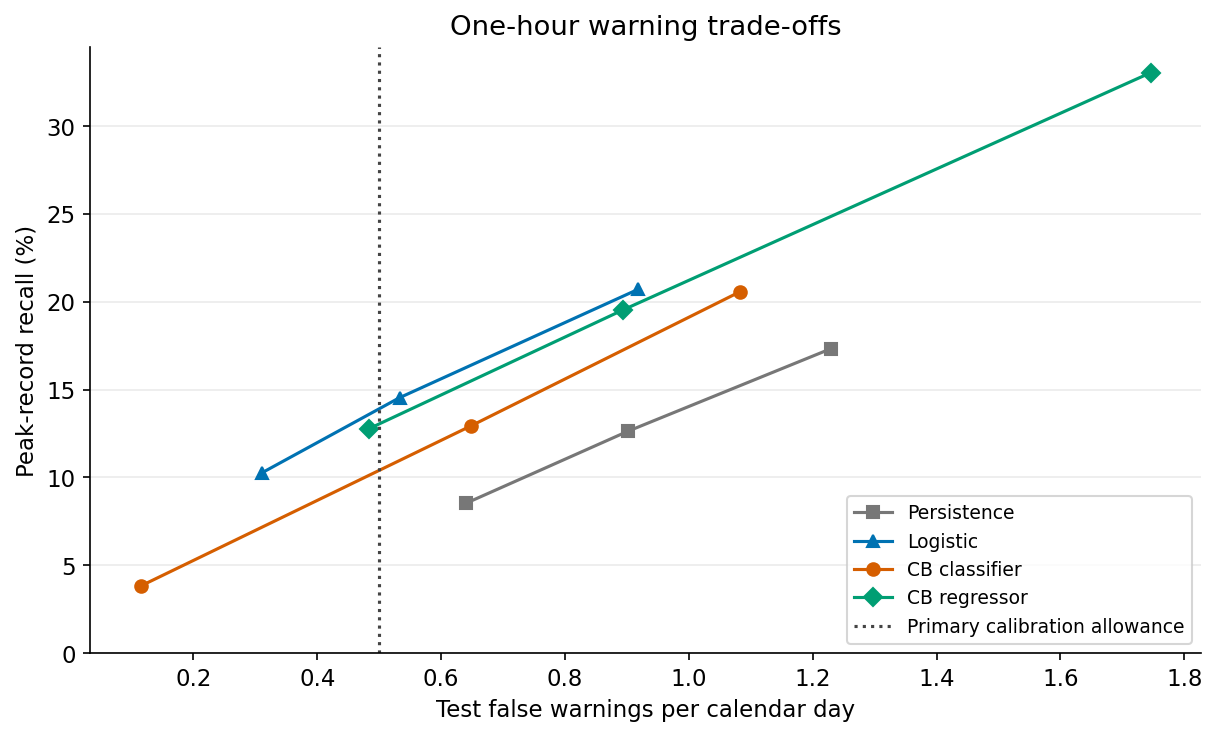

In [5]:
styles = {'Persistence': ('#777777', 's'), 'Logistic': ('#0072B2', '^'), 'CB classifier': ('#D55E00', 'o'), 'CB regressor': ('#009E73', 'D')}
fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
for method, (color, marker) in styles.items():
    points = metrics.query("protocol == 'origin_safe' and horizon_hours == 1 and method == @method").sort_values('budget')
    ax.plot(points.false_per_day, 100 * points.recall, color=color, marker=marker, label=method)
ax.axvline(0.5, color='#444444', linestyle=':', label='Primary calibration allowance')
ax.set(xlabel='Test false warnings per calendar day', ylabel='Peak-record recall (%)', ylim=(0, None), title='One-hour warning trade-offs')
ax.grid(axis='y', alpha=0.25)
ax.legend(fontsize=9)
plt.show()

The regressor's higher observed recall comes with more false warnings than logistic regression. None of the six primary one-hour operating points retains the historical 0.5-per-day allowance on the test period. The regressor detects 27 of 228 onsets (11.8%); this limits the evidence for operational usefulness.

### Transfer over test months

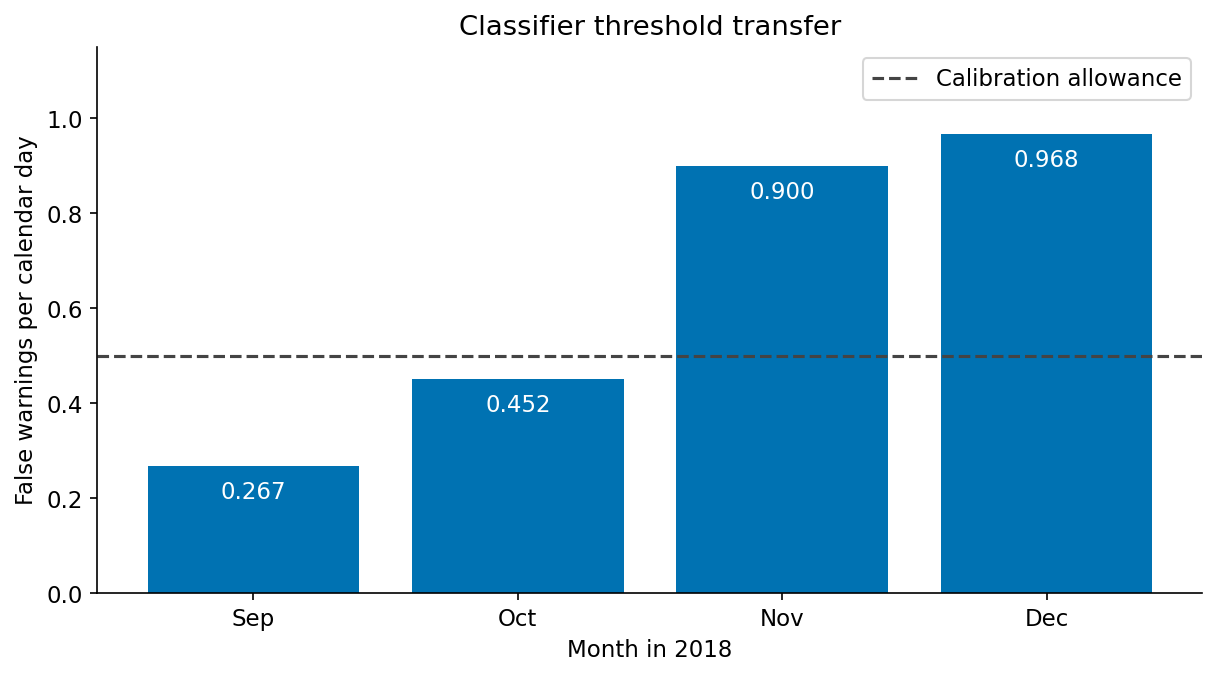

,month,records,peaks,tp,fp,recall,false_per_day
0,9,2876,136,13,8,0.096,0.267
1,10,2976,243,13,14,0.053,0.452
2,11,2880,237,31,27,0.131,0.900
3,12,2976,65,31,30,0.477,0.968


In [6]:
monthly = pd.read_csv(RESULTS / 'monthly_metrics.csv')
monthly_main = monthly.query("protocol == 'origin_safe' and horizon_hours == 1 and method == 'CB classifier' and budget == 0.5")
fig, ax = plt.subplots(figsize=(8, 4.4), constrained_layout=True)
bars = ax.bar(['Sep', 'Oct', 'Nov', 'Dec'], monthly_main.false_per_day, color='#0072B2')
ax.bar_label(bars, fmt='%.3f', padding=-18, color='white')
ax.axhline(0.5, linestyle='--', color='#444444', label='Calibration allowance')
ax.set(xlabel='Month in 2018', ylabel='False warnings per calendar day', ylim=(0, 1.15), title='Classifier threshold transfer')
ax.legend()
plt.show()
display(monthly_main[['month', 'records', 'peaks', 'tp', 'fp', 'recall', 'false_per_day']].round(3).reset_index(drop=True))

The classifier's false-warning rate increases across these four months. This descriptive pattern does not identify the cause; production regimes and seasonal changes are hypotheses, and operating-state data were not included.

### All lead times and paired uncertainty

In [7]:
display(metrics.query("protocol == 'origin_safe' and budget == 0.5")[['horizon_hours', 'method', 'recall', 'false_per_day', 'average_precision']].round(4).reset_index(drop=True))
intervals = pd.read_csv(RESULTS / 'bootstrap_intervals.csv')
display(intervals.query("protocol == 'origin_safe' and method in ['Logistic', 'CB classifier', 'CB regressor']").round(4).reset_index(drop=True))
paired = pd.read_csv(RESULTS / 'paired_recall_intervals.csv')
display(paired.query("protocol == 'origin_safe'").round(4).reset_index(drop=True))

,horizon_hours,method,recall,false_per_day,average_precision
0,1.0,Persistence,0.1263,0.9016,0.3298
1,1.0,Previous day,0.0426,1.2131,0.1416
2,1.0,Previous week,0.0514,1.1230,0.1707
3,1.0,Logistic,0.1454,0.5328,0.4050
4,1.0,CB classifier,0.1292,0.6475,0.4385
5,1.0,CB regressor,0.1953,0.8934,0.4403
6,2.0,Persistence,0.0866,1.0164,0.2059
7,2.0,Previous day,0.0426,1.2131,0.1416
8,2.0,Previous week,0.0514,1.1230,0.1707
9,2.0,Logistic,0.1057,0.5656,0.2804


,protocol,method,metric,lower,upper,replicates
0,origin_safe,Logistic,recall,0.0855,0.2215,2000
1,origin_safe,Logistic,false_per_day,0.3443,0.7131,2000
2,origin_safe,CB classifier,recall,0.0720,0.2046,2000
3,origin_safe,CB classifier,false_per_day,0.3770,0.9918,2000
4,origin_safe,CB regressor,recall,0.1103,0.2914,2000
5,origin_safe,CB regressor,false_per_day,0.5410,1.2787,2000


,protocol,contrast,lower,upper
0,origin_safe,CB classifier minus Logistic,-0.0760,0.0434
1,origin_safe,CB classifier minus CB regressor,-0.1093,-0.0206
2,origin_safe,CB regressor minus Logistic,-0.0229,0.1214
3,origin_safe,CB regressor minus Persistence,0.0064,0.1425


Bootstrap resamples 122 daily records in seven-day circular blocks, with the same indices for all methods. It is conditional on the fitted models and calibrated thresholds. Intervals do not establish validity under future distribution shift.

### Audit against the earlier manuscript

Every reported number encoded in the audit is compared at its printed precision. Differences remain visible; the earlier CatBoost values are not used to tune this reconstruction.

In [8]:
comparison = pd.read_csv(RESULTS / 'manuscript_comparison.csv')
display(comparison.groupby('protocol')['matches_reported_rounding'].agg(['sum', 'count']))
display(comparison.loc[~comparison.matches_reported_rounding].head(18))

,sum,count
protocol,,
legacy,44,89
origin_safe,38,89
source,7,7


,protocol,comparison_role,location,method,horizon_hours,budget,month,segment,contrast,metric,interval_metric,unit,reported,reported_decimals,recomputed,delta,matches_reported_rounding,status,source_file
32,legacy,direct_manuscript_comparison,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,recall,NaN,percent,10.600,1,12.922173,2.322173,False,mismatch,metrics.csv
33,origin_safe,modified_protocol_reference,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,recall,NaN,percent,10.600,1,12.922173,2.322173,False,mismatch,metrics.csv
34,legacy,direct_manuscript_comparison,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,precision,NaN,percent,48.300,1,52.694611,4.394611,False,mismatch,metrics.csv
35,origin_safe,modified_protocol_reference,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,precision,NaN,percent,48.300,1,52.694611,4.394611,False,mismatch,metrics.csv
36,legacy,direct_manuscript_comparison,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,false_per_day,NaN,false/calendar_day,0.631,3,0.647541,0.016541,False,mismatch,metrics.csv
37,origin_safe,modified_protocol_reference,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,false_per_day,NaN,false/calendar_day,0.631,3,0.647541,0.016541,False,mismatch,metrics.csv
38,legacy,direct_manuscript_comparison,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,average_precision,NaN,score,0.426,3,0.438499,0.012499,False,mismatch,metrics.csv
39,origin_safe,modified_protocol_reference,Table I,CB classifier,1.0,0.5,NaN,NaN,NaN,average_precision,NaN,score,0.426,3,0.438499,0.012499,False,mismatch,metrics.csv
40,legacy,direct_manuscript_comparison,Table I,CB regressor,1.0,0.5,NaN,NaN,NaN,recall,NaN,percent,16.900,1,19.530103,2.630103,False,mismatch,metrics.csv
41,origin_safe,modified_protocol_reference,Table I,CB regressor,1.0,0.5,NaN,NaN,NaN,recall,NaN,percent,16.900,1,19.530103,2.630103,False,mismatch,metrics.csv


## Takeaways

- The source data, simple baselines, and primary logistic operating point agree with the manuscript; CatBoost outcomes differ under the explicit reconstruction choices.
- The repository provides an executable reference implementation and transparent comparison, not recovered historical code.
- The revised paper should cite the exact repository commit and use recomputed values consistently.
- One facility and one year, weak onset detection, and no intervention-cost data limit deployment conclusions. A real installation needs operational peak limits, action-specific warning budgets, and later-period validation.